In [3]:
pip install minisom

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


SOM Training Completed!
Input: [0. 0.] BMU: (np.int64(0), np.int64(0))
Input: [0.    0.125] BMU: (np.int64(0), np.int64(3))
Input: [0.125 0.   ] BMU: (np.int64(0), np.int64(1))
Input: [0.125 0.125] BMU: (np.int64(0), np.int64(2))
Input: [0.875 0.875] BMU: (np.int64(2), np.int64(2))
Input: [0.875 1.   ] BMU: (np.int64(3), np.int64(1))
Input: [1.    0.875] BMU: (np.int64(3), np.int64(3))
Input: [1. 1.] BMU: (np.int64(4), np.int64(3))


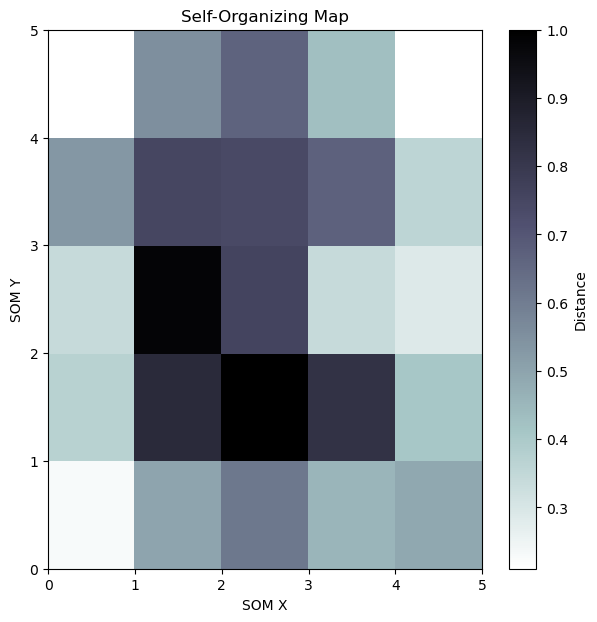

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from minisom import MiniSom

# Input data
data = np.array([
    [1, 1],
    [1, 2],
    [2, 1],
    [2, 2],
    [8, 8],
    [8, 9],
    [9, 8],
    [9, 9]
])

# Normalize data
data = (data - np.min(data, axis=0)) / (
    np.max(data, axis=0) - np.min(data, axis=0)
)

# Create SOM
som = MiniSom(
    x=5,
    y=5,
    input_len=2,
    sigma=1.0,
    learning_rate=0.5
)

# Initialize weights
som.random_weights_init(data)

# Train SOM
som.train_random(data, 100)

print("SOM Training Completed!")

# Display BMU for each input
for sample in data:
    bmu = som.winner(sample)
    print("Input:", sample, "BMU:", bmu)

# Plot SOM distance map
plt.figure(figsize=(7, 7))
plt.pcolor(som.distance_map().T, cmap='bone_r')
plt.colorbar(label='Distance')

plt.title("Self-Organizing Map")
plt.xlabel("SOM X")
plt.ylabel("SOM Y")

plt.show()